# PREPARAMOS DATOS

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

ruta_csv = r"c:\Users\Cristian\Downloads\Clase 8-10 python\PuntosCalor_limpio.csv"

df = pd.read_csv(ruta_csv, encoding="utf-8-sig")

df["acq_date"] = pd.to_datetime(df["acq_date"], errors="coerce")
df["departamen"] = df["departamen"].astype("string").str.strip().str.upper()
df["municipio"] = df["municipio"].astype("string").str.strip().str.upper()

df = df.dropna(
    subset=["latitude", "longitude", "departamen", "acq_date"]
).copy()

df["anio"] = df["acq_date"].dt.year
df["mes"] = df["acq_date"].dt.month

print("Registros:", len(df))
display(df.head())

Registros: 447213


,X,Y,objectid,latitude,longitude,fecha_date,acq_date,departamen,municipio,paisaje,car,leyenda,anio,mes
0,-7.855260e+06,448541.5301,72227,4.026,-70.565,2014-01-01,2014-01-01,VICHADA,CUMARIBO,llanura,corporinoquia,resguardo indigena,2014,1
1,-7.855816e+06,448764.7202,72228,4.028,-70.570,2014-01-01,2014-01-01,VICHADA,CUMARIBO,llanura,corporinoquia,resguardo indigena,2014,1
2,-7.650766e+06,516194.4697,72502,4.632,-68.728,2014-01-01,2014-01-01,VICHADA,CUMARIBO,llanura,corporinoquia,resguardo indigena,2014,1
3,-7.620821e+06,525353.1131,72529,4.714,-68.459,2014-01-01,2014-01-01,VICHADA,CUMARIBO,llanura,corporinoquia,resguardo indigena,2014,1
4,-7.621600e+06,526470.0944,72534,4.724,-68.466,2014-01-01,2014-01-01,VICHADA,CUMARIBO,llanura,corporinoquia,resguardo indigena,2014,1


# ZONAS QUE PODRIAN PRESENTARSE MAS INCEDIOS

Zonas con mayor concentración histórica:


,lat_celda,lon_celda,incendios
274,1.25,-74.50,13349
248,1.00,-74.50,10535
387,2.25,-74.25,9766
300,1.50,-74.50,9198
491,3.25,-71.75,8047
360,2.00,-73.75,7462
365,2.00,-72.50,7247
336,1.75,-72.50,6855
361,2.00,-73.50,6484
218,0.75,-75.00,6428


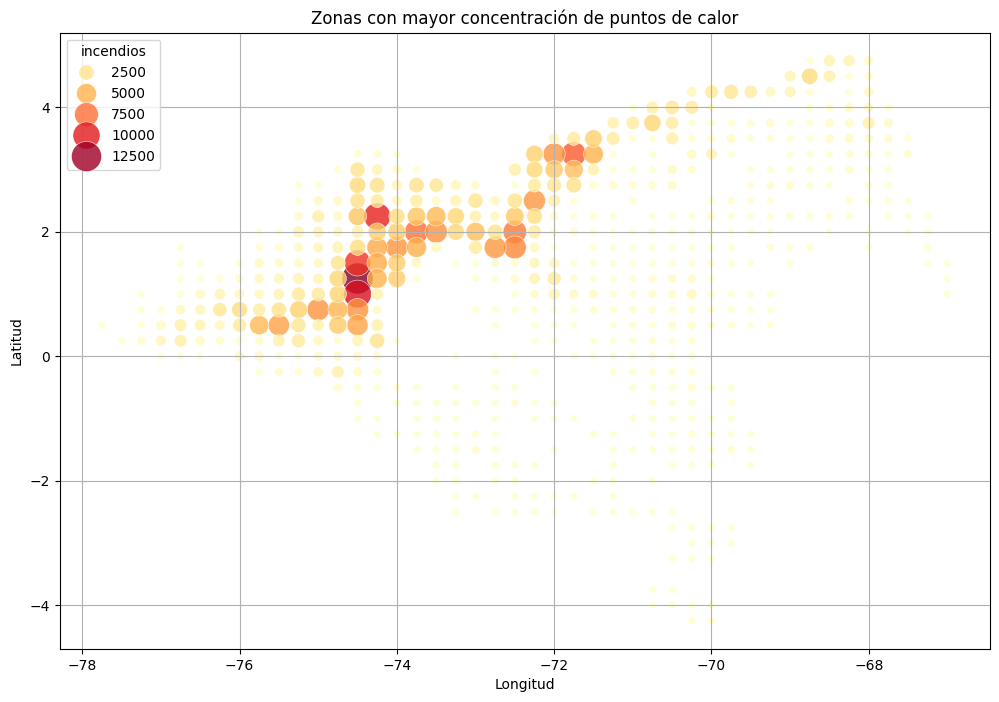

In [2]:
# Crear cuadrículas geográficas
tamano_celda = 0.25

df["lat_celda"] = (
    np.floor(df["latitude"] / tamano_celda) * tamano_celda
)

df["lon_celda"] = (
    np.floor(df["longitude"] / tamano_celda) * tamano_celda
)

zonas = (
    df.groupby(["lat_celda", "lon_celda"])
    .size()
    .reset_index(name="incendios")
    .sort_values("incendios", ascending=False)
)

print("Zonas con mayor concentración histórica:")
display(zonas.head(10))

# Visualizar las zonas de mayor riesgo histórico
plt.figure(figsize=(12, 8))

sns.scatterplot(
    data=zonas,
    x="lon_celda",
    y="lat_celda",
    size="incendios",
    hue="incendios",
    sizes=(30, 500),
    palette="YlOrRd",
    alpha=0.8
)

plt.title("Zonas con mayor concentración de puntos de calor")
plt.xlabel("Longitud")
plt.ylabel("Latitud")
plt.grid(True)
plt.show()

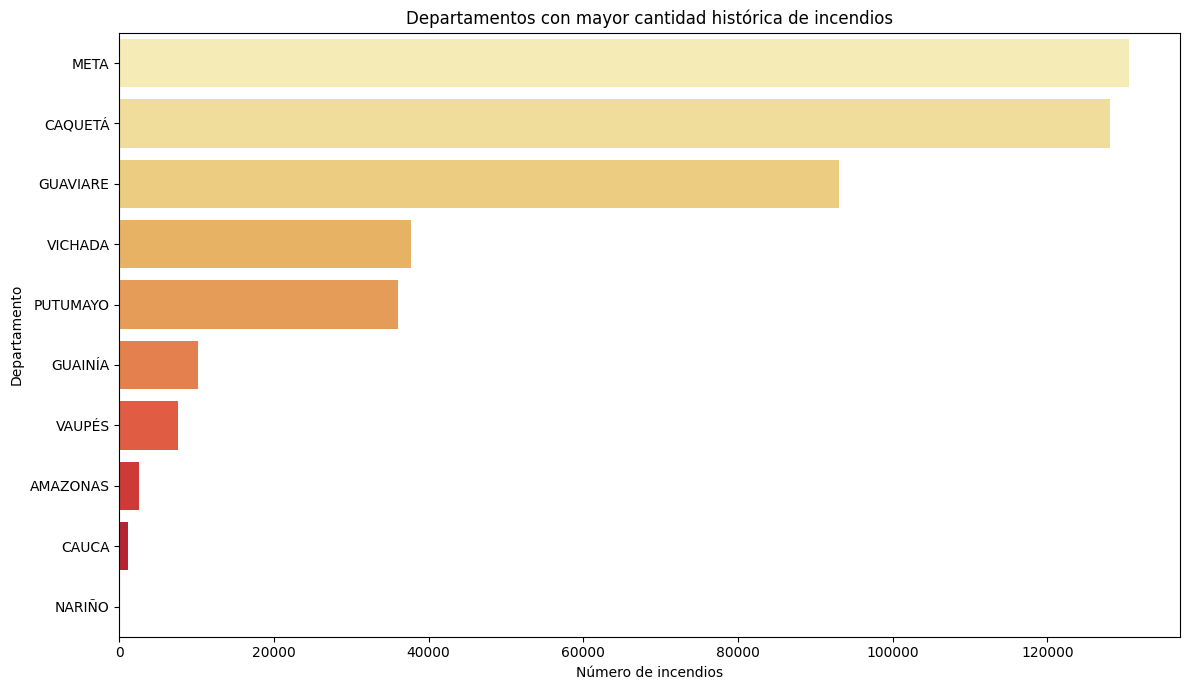

In [3]:
# Departamentos con mayor cantidad de incendios
incendios_departamento = (
    df.groupby("departamen")
    .size()
    .reset_index(name="incendios")
    .sort_values("incendios", ascending=False)
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=incendios_departamento.head(15),
    x="incendios",
    y="departamen",
    hue="departamen",
    palette="YlOrRd",
    legend=False
)

plt.title("Departamentos con mayor cantidad histórica de incendios")
plt.xlabel("Número de incendios")
plt.ylabel("Departamento")
plt.tight_layout()
plt.show()

#  ¿Cuántos incendios podrían ocurrir en un departamento?

In [5]:
%pip install scikit-learn

     ---------------------------------------- 8.9/8.9 MB 6.2 MB/s eta 0:00:00
     -------------------------------------- 306.1/306.1 kB 4.8 MB/s eta 0:00:00
     ---------------------------------------- 41.3/41.3 MB 2.5 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip available: 22.2.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [9]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Agrupar incendios por departamento, año y mes
datos_modelo = (
    df.groupby(["departamen", "anio", "mes"])
    .size()
    .reset_index(name="cantidad_incendios")
)

# Variables explicativas y variable objetivo
X = datos_modelo[["departamen", "anio", "mes"]]
y = datos_modelo["cantidad_incendios"]

X_entrenamiento, X_prueba, y_entrenamiento, y_prueba = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

preprocesamiento = ColumnTransformer(
    transformers=[
        (
            "departamento",
            OneHotEncoder(handle_unknown="ignore"),
            ["departamen"]
        ),
        (
            "numericas",
            SimpleImputer(strategy="median"),
            ["anio", "mes"]
        )
    ]
)

modelo = Pipeline([
    ("preprocesamiento", preprocesamiento),
    (
        "regresor",
        RandomForestRegressor(
            n_estimators=300,
            random_state=42,
            min_samples_leaf=2
        )
    )
])

modelo.fit(X_entrenamiento, y_entrenamiento)

predicciones = modelo.predict(X_prueba)

mae = mean_absolute_error(y_prueba, predicciones)
rmse = np.sqrt(mean_squared_error(y_prueba, predicciones))

print("Error absoluto medio:", round(mae, 2))
print("RMSE:", round(rmse, 2))

Error absoluto medio: 295.39
RMSE: 940.79


In [ ]:
# Predecir incendios mensuales para el siguiente año
ultimo_anio = int(df["anio"].max())
anio_prediccion = ultimo_anio + 1

departamentos = sorted(df["departamen"].dropna().unique())

futuro = pd.DataFrame([
    {
        "departamen": departamento,
        "anio": anio_prediccion,
        "mes": mes
    }
    for departamento in departamentos
    for mes in range(1, 13)
])

futuro["prediccion_incendios"] = modelo.predict(futuro)

# Sumar la predicción mensual para obtener el total anual por departamento
prediccion_departamento = (
    futuro.groupby("departamen")["prediccion_incendios"]
    .sum()
    .round()
    .astype(int)
    .reset_index()
    .sort_values("prediccion_incendios", ascending=False)
)

prediccion_departamento = prediccion_departamento.rename(
    columns={"prediccion_incendios": "incendios_estimados"}
)

display(prediccion_departamento)

,departamen,incendios_estimados
5,META,17706
1,CAQUETÁ,14599
4,GUAVIARE,11300
9,VICHADA,5202
7,PUTUMAYO,4878
3,GUAINÍA,1457
8,VAUPÉS,982
0,AMAZONAS,461
2,CAUCA,295
6,NARIÑO,242


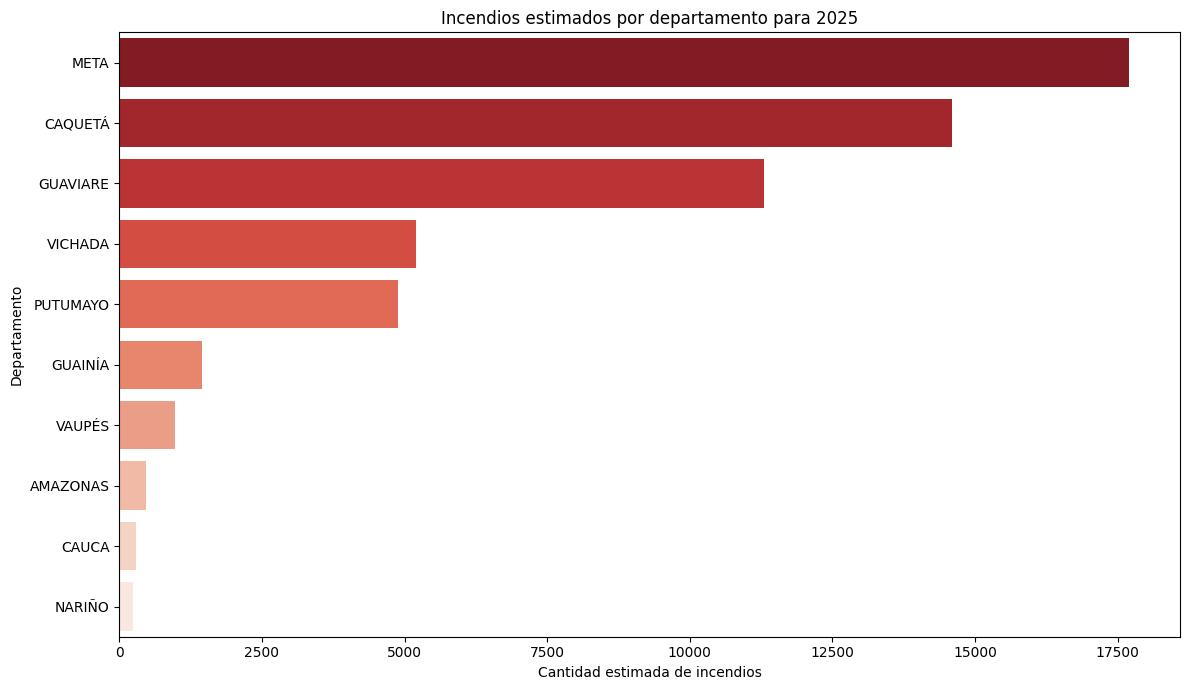

In [11]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=prediccion_departamento.head(15),
    x="incendios_estimados",
    y="departamen",
    hue="departamen",
    palette="Reds_r",
    legend=False
)

plt.title(
    f"Incendios estimados por departamento para {anio_prediccion}"
)
plt.xlabel("Cantidad estimada de incendios")
plt.ylabel("Departamento")
plt.tight_layout()
plt.show()